# 2.2 Exploration : Dataset 2

Extrait final de RVL-CDIP : 60 000 images, 6 classes de 10 000 images
(`email`, `form`, `invoice`, `presentation`, `resume`, `scientific_report`).

Le premier extrait (30 000 images, 5 000 par classe, dossier `rvl_cdip_filtered_dataset_2`)
contient les mêmes 6 classes.

Les fonctions utilisées sont dans [outils_2.py](outils_2.py).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from outils_2 import list_images, add_visual_metrics, show_mosaic, values_by_class

DOSSIER = "../data/rvl_cdip_filtered_dataset_3"

## Chargement des images et calcul des 6 métriques visuelles (environ 3 minutes)

In [2]:
df = list_images(DOSSIER)
df = add_visual_metrics(df)
print(len(df), "images")
df.head()

  0%|          | 0/60000 [00:00<?, ?it/s]

  0%|          | 25/60000 [00:00<04:03, 246.26it/s]

  0%|          | 52/60000 [00:00<03:52, 258.25it/s]

  0%|          | 81/60000 [00:00<03:43, 268.22it/s]

  0%|          | 110/60000 [00:00<03:39, 272.30it/s]

...

100%|█████████▉| 59969/60000 [03:07<00:00, 299.06it/s]

100%|██████████| 60000/60000 [03:07<00:00, 299.21it/s]

100%|██████████| 60000/60000 [03:07<00:00, 319.25it/s]

60000 images


,filepath,label,width,height,brightness,contrast,dark_ratio,aspect_ratio
0,../data/rvl_cdip_filtered_dataset_3/form/form_...,form,779,1000,238.104889,52.461803,0.062698,0.779
1,../data/rvl_cdip_filtered_dataset_3/form/form_...,form,777,1000,245.358429,41.451939,0.037450,0.777
2,../data/rvl_cdip_filtered_dataset_3/form/form_...,form,754,1000,228.795929,68.360916,0.101629,0.754
3,../data/rvl_cdip_filtered_dataset_3/form/form_...,form,715,1000,241.333908,44.596489,0.052498,0.715
4,../data/rvl_cdip_filtered_dataset_3/form/form_...,form,777,1000,247.301453,36.838463,0.029723,0.777


## Fig. 1 : Répartition des classes

Test du Chi² : les classes ont-elles le même effectif ?

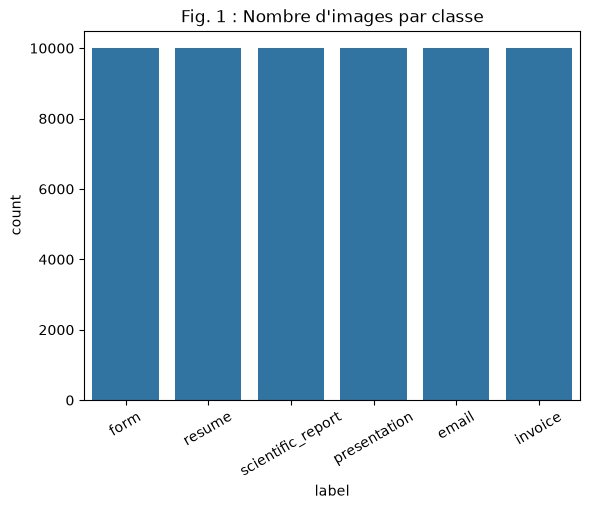

Chi² = 0.00   p-value = 1.0000


In [3]:
sns.countplot(data=df, x="label")
plt.xticks(rotation=30)
plt.title("Fig. 1 : Nombre d'images par classe")
plt.show()

chi2, p = stats.chisquare(df["label"].value_counts())
print(f"Chi² = {chi2:.2f}   p-value = {p:.4f}")

## Fig. 2 : Exemples d'images par classe

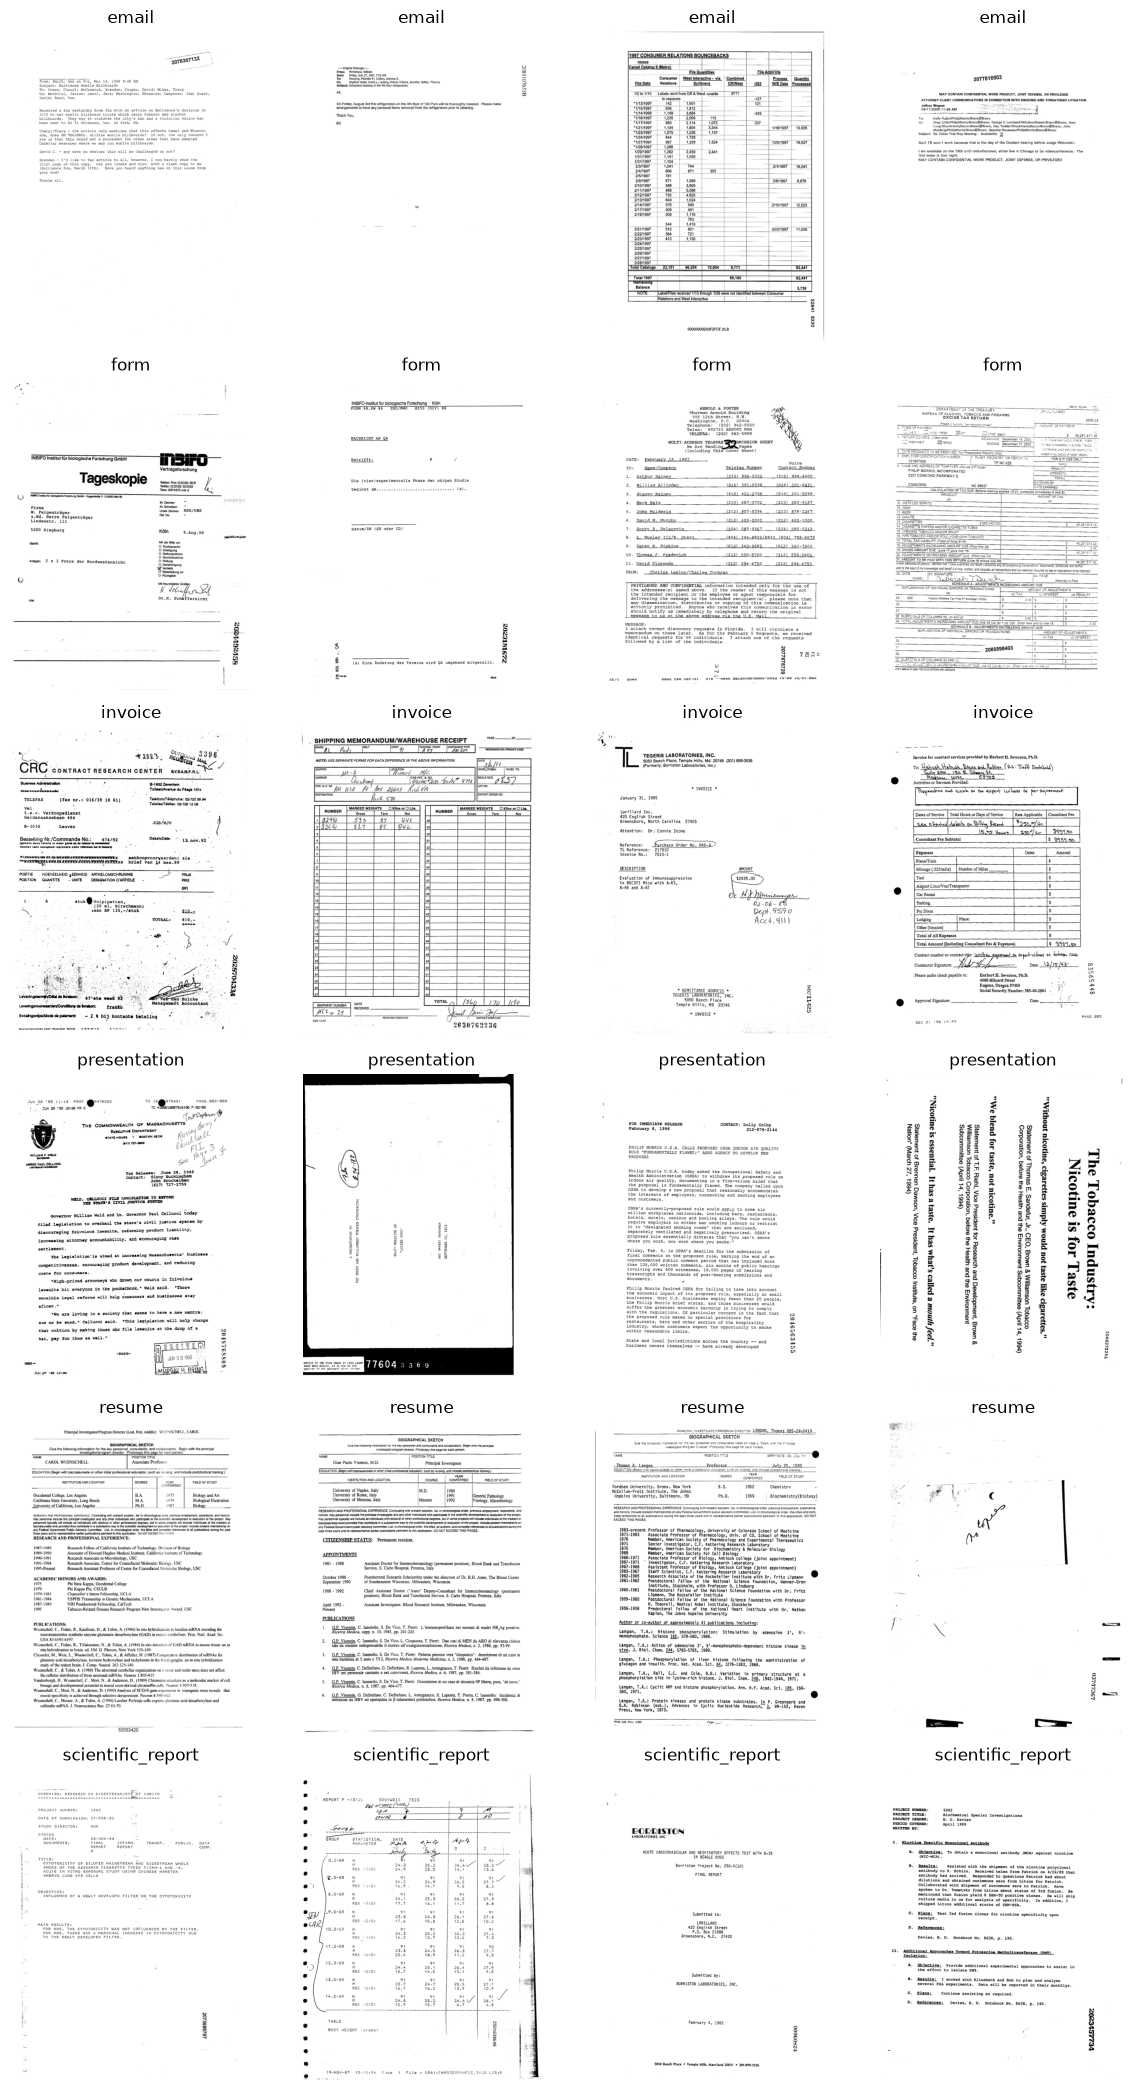

In [4]:
show_mosaic(df)

## Fig. 3 : Résolution des images

ANOVA : la largeur moyenne change-t-elle selon la classe ?

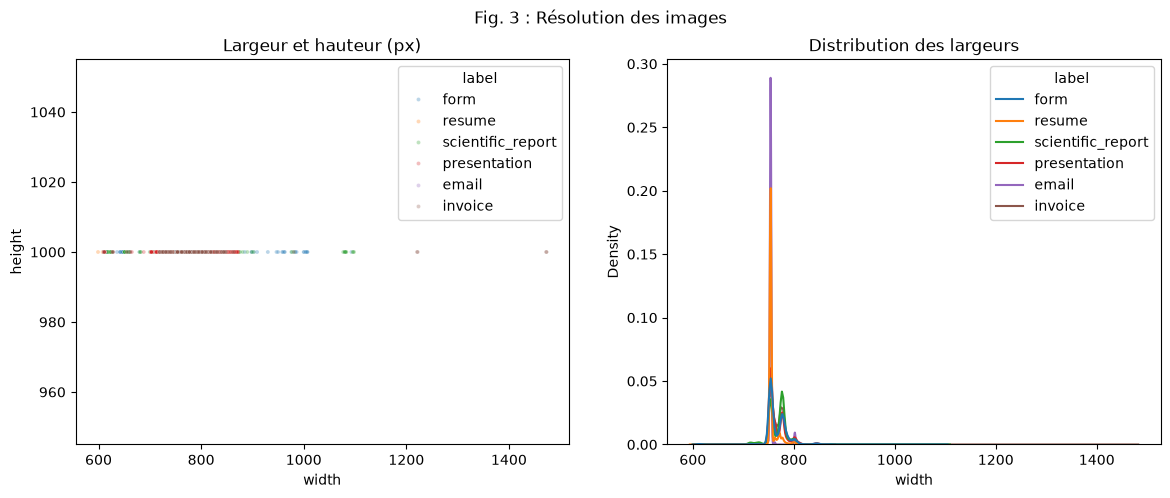

ANOVA largeurs : F = 887.08   p-value = 0.0000
Largeur : min = 599 px, max = 1473 px


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="width", y="height", hue="label", s=8, alpha=0.3, ax=axes[0])
axes[0].set_title("Largeur et hauteur (px)")
sns.kdeplot(data=df, x="width", hue="label", common_norm=False, ax=axes[1])
axes[1].set_title("Distribution des largeurs")
plt.suptitle("Fig. 3 : Résolution des images")
plt.show()

f, p = stats.f_oneway(*values_by_class(df, "width"))
print(f"ANOVA largeurs : F = {f:.2f}   p-value = {p:.4f}")
print(f"Largeur : min = {df['width'].min()} px, max = {df['width'].max()} px")

## Fig. 4 : Qualité des scans : luminosité et contraste

Kruskal-Wallis : la luminosité change-t-elle selon la classe ?

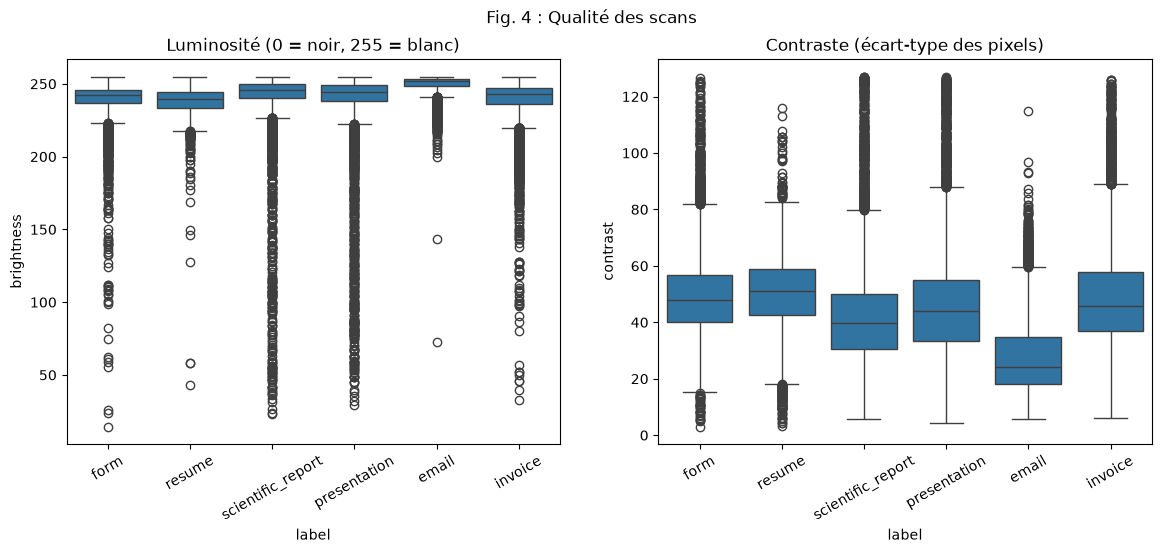

Kruskal-Wallis luminosité : H = 14144.80   p-value = 0.0000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="label", y="brightness", ax=axes[0])
axes[0].set_title("Luminosité (0 = noir, 255 = blanc)")
sns.boxplot(data=df, x="label", y="contrast", ax=axes[1])
axes[1].set_title("Contraste (écart-type des pixels)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Fig. 4 : Qualité des scans")
plt.show()

h, p = stats.kruskal(*values_by_class(df, "brightness"))
print(f"Kruskal-Wallis luminosité : H = {h:.2f}   p-value = {p:.4f}")

## Fig. 5 : Densité d'encre et format

Mann-Whitney : on compare la classe la moins dense en encre à la plus dense.
Zoom sur 0 à 0,3 pour la densité : quelques pages presque noires montent jusqu'à 0,95.

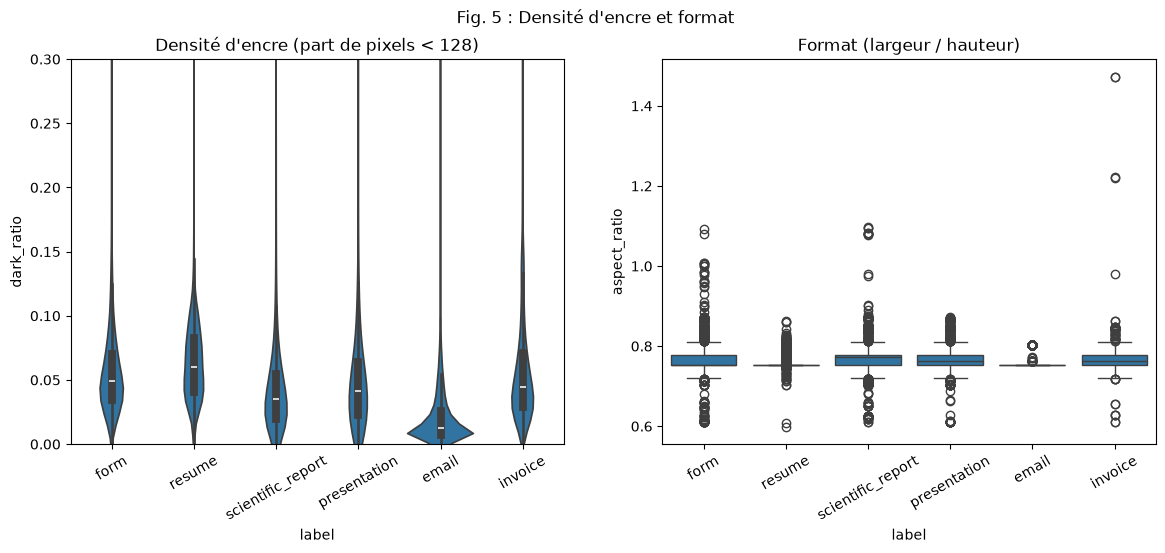

Mann-Whitney email vs resume : U = 9992482   p-value = 0.0000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=df, x="label", y="dark_ratio", ax=axes[0])
axes[0].set_ylim(0, 0.3)
axes[0].set_title("Densité d'encre (part de pixels < 128)")
sns.boxplot(data=df, x="label", y="aspect_ratio", ax=axes[1])
axes[1].set_title("Format (largeur / hauteur)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Fig. 5 : Densité d'encre et format")
plt.show()

medianes = df.groupby("label")["dark_ratio"].median().sort_values()
moins_dense, plus_dense = medianes.index[0], medianes.index[-1]
u, p = stats.mannwhitneyu(df.loc[df["label"] == moins_dense, "dark_ratio"],
                          df.loc[df["label"] == plus_dense, "dark_ratio"])
print(f"Mann-Whitney {moins_dense} vs {plus_dense} : U = {u:.0f}   p-value = {p:.4f}")

## Fig. 6 : Séparabilité des classes : PCA et corrélations

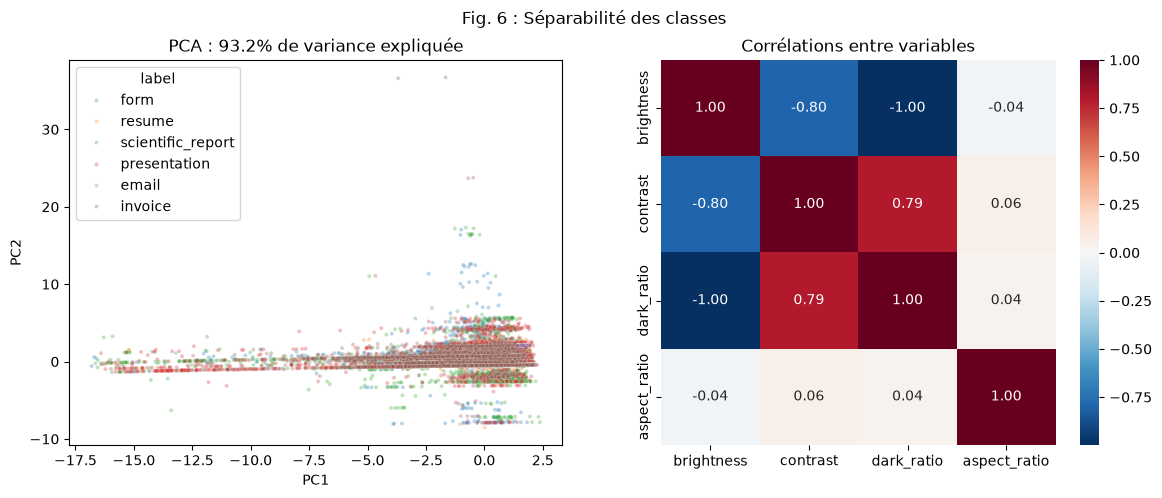

,PC1,PC2
brightness,0.593,0.034
contrast,-0.544,-0.002
dark_ratio,-0.592,-0.036
aspect_ratio,-0.043,0.999


In [8]:
VARIABLES = ["brightness", "contrast", "dark_ratio", "aspect_ratio"]
X = StandardScaler().fit_transform(df[VARIABLES])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["label"], s=8, alpha=0.3, ax=axes[0])
axes[0].set_title(f"PCA : {pca.explained_variance_ratio_.sum():.1%} de variance expliquée")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
sns.heatmap(df[VARIABLES].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Corrélations entre variables")
plt.suptitle("Fig. 6 : Séparabilité des classes")
plt.show()

# poids de chaque variable sur les 2 axes
pd.DataFrame(pca.components_.T, index=VARIABLES, columns=["PC1", "PC2"]).round(3)

## Fig. 7 : Distribution de chacune des 6 métriques par classe

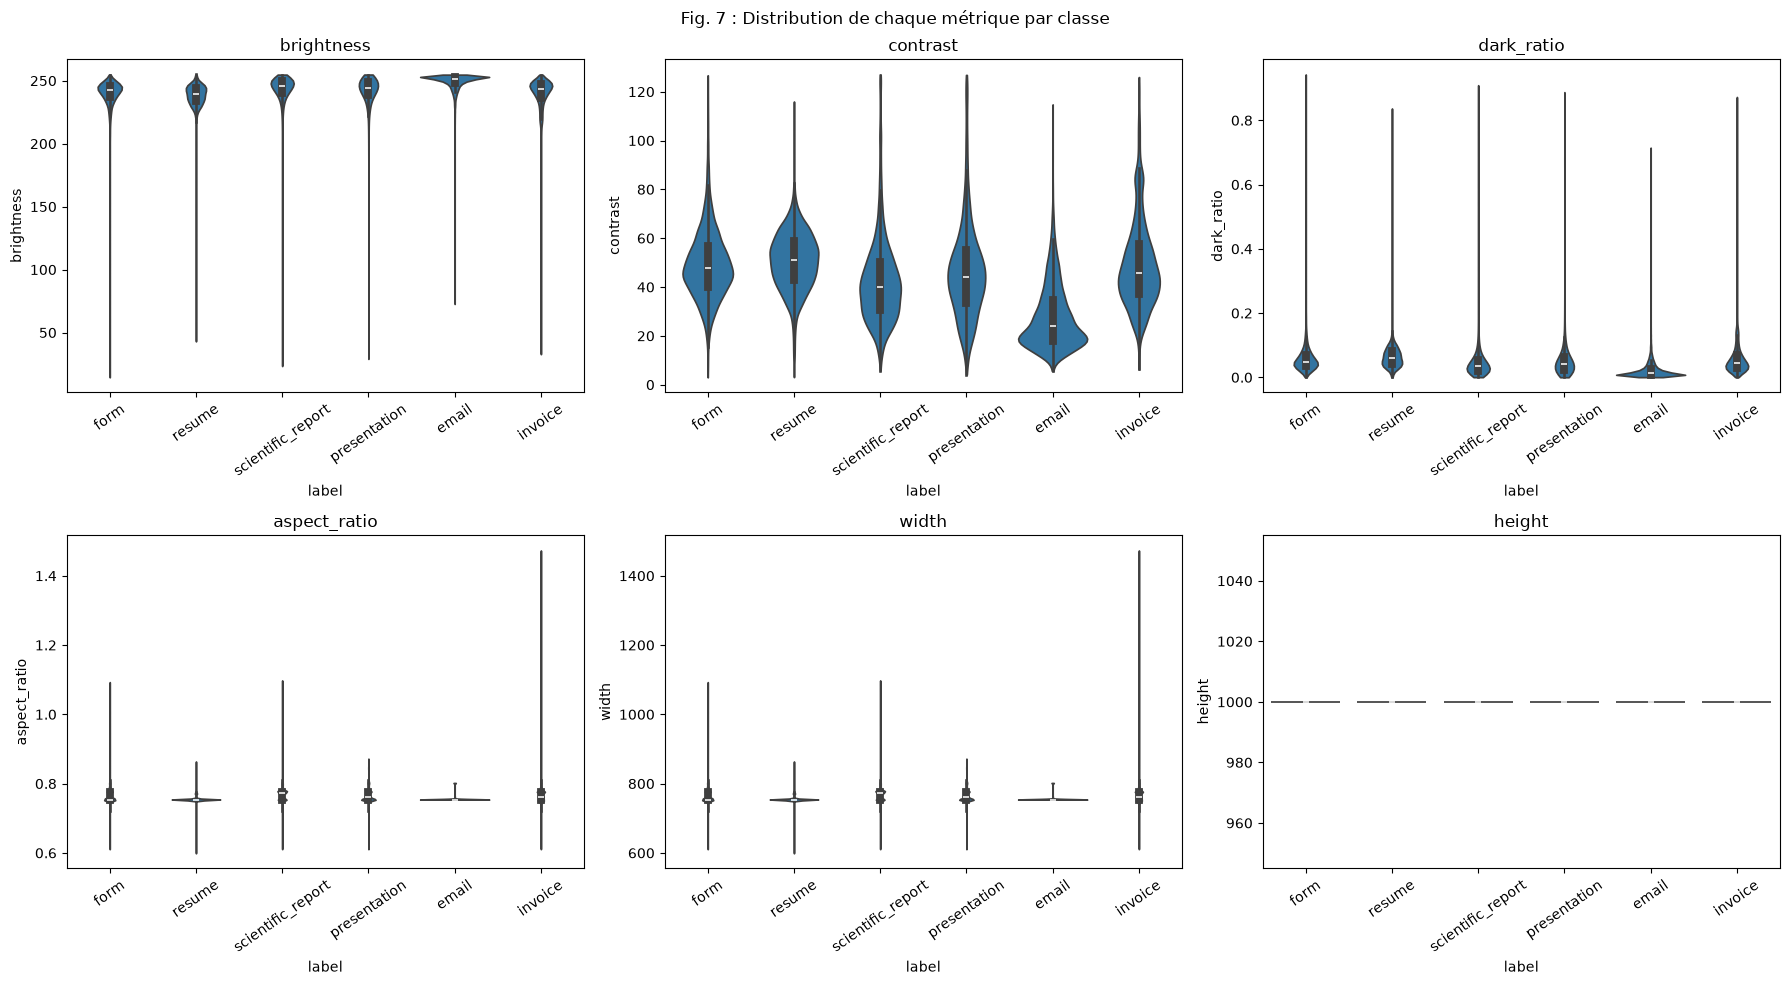

,brightness,contrast,dark_ratio,aspect_ratio,width,height
label,,,,,,
email,251.649994,24.009001,0.013,0.754,754.0,1000.0
form,242.248001,47.756001,0.049,0.754,754.0,1000.0
invoice,243.248993,45.907001,0.045,0.762,762.0,1000.0
presentation,244.307999,44.123001,0.041,0.762,762.0,1000.0
resume,239.264008,51.042999,0.060,0.754,754.0,1000.0
scientific_report,245.806000,39.832001,0.035,0.773,773.0,1000.0


In [9]:
METRIQUES = ["brightness", "contrast", "dark_ratio", "aspect_ratio", "width", "height"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, metrique in zip(axes.flat, METRIQUES):
    sns.violinplot(data=df, x="label", y=metrique, cut=0, ax=ax)
    ax.set_title(metrique)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Fig. 7 : Distribution de chaque métrique par classe")
plt.tight_layout()
plt.show()

df.groupby("label")[METRIQUES].median().round(3)

## Synthèse

Kruskal-Wallis : la densité d'encre et le format changent-ils selon la classe ?

In [10]:
for metrique in ["dark_ratio", "aspect_ratio"]:
    h, p = stats.kruskal(*values_by_class(df, metrique))
    print(f"Kruskal-Wallis {metrique} : H = {h:.2f}   p-value = {p:.4f}")

print("Images très sombres (luminosité < 50) :", (df["brightness"] < 50).sum())
print(f"Score d'un classement au hasard : 1/6 = {1/6:.1%}")

Kruskal-Wallis dark_ratio : H = 14153.95   p-value = 0.0000
Kruskal-Wallis aspect_ratio : H = 9884.40   p-value = 0.0000
Images très sombres (luminosité < 50) : 43
Score d'un classement au hasard : 1/6 = 16.7%
